In [1]:
import site
import sys
import subprocess
import os

# 1. Registrar la ruta de paquetes del usuario en el sistema
user_site = '/headless/.local/lib/python3.12/site-packages'
if os.path.exists(user_site):
    site.addsitedir(user_site)

# 2. Intentar importar; si falla, instalarlo automáticamente
try:
    from PyLTSpice import RawRead
    print('¡PyLTSpice ya estaba instalado y listo para usar!')
except ImportError:
    print('PyLTSpice no fue encontrado. Instalando automáticamente...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--user', 'PyLTSpice'])
    if os.path.exists(user_site):
        site.addsitedir(user_site)
    from PyLTSpice import RawRead
    print('¡PyLTSpice se instaló e importó correctamente!')

¡PyLTSpice ya estaba instalado y listo para usar!


In [2]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import scipy.stats as stats
import os

# ==============================================================================
# 1. CARGAR Y EXTRAER LOS DATOS
# ==============================================================================
# Ruta por defecto de Xschem (cámbiala si usaste una ruta absoluta en el código)
ruta_archivo = "/headless/.xschem/simulations/datos_mc.txt"

if not os.path.exists(ruta_archivo):
    print(f"⚠️ Archivo no encontrado en: {ruta_archivo}")
else:
    with open(ruta_archivo, 'r') as f:
        texto = f.read()

    # Función auxiliar para extraer números con Regex
    # Busca el nombre exacto y atrapa cualquier número (+, -, decimales, exponentes)
    def extraer(variable, texto):
        patron = rf"{variable}\s*=\s*([\d\.\-eE\+]+)"
        encontrados = re.findall(patron, texto)
        return [float(x) for x in encontrados]

    # Diccionario con todos los parámetros que mediste en Ngspice
    datos_extraidos = {
        'Dropout (mV)': extraer('dropout_mV', texto),
        'Margen Fase (Deg)': extraer('margen_fase', texto),
        'UGB (Hz)': extraer('ugb', texto),
        'Overshoot (mV)': extraer('overshoot_mV', texto),
        'Undershoot (mV)': extraer('undershoot_mV', texto),
        'Load Reg (mV)': extraer('load_regulation', texto),
        'Line Reg (mV)': extraer('line_regulation', texto),
        'PSRR 1k (dB)': extraer('psrr_1k', texto),
        'PSRR 10k (dB)': extraer('psrr_10k', texto),
    }

    # Creamos el DataFrame. Usamos orient='index' y transponemos (.T) por si 
    # alguna simulación falló y una columna tiene menos datos que otra.
    df_mc = pd.DataFrame.from_dict(datos_extraidos, orient='index').T

    # Mostramos las primeras 10 corridas
    display(df_mc.head(10))



,Dropout (mV),Margen Fase (Deg),UGB (Hz),Overshoot (mV),Undershoot (mV),Load Reg (mV),Line Reg (mV),PSRR 1k (dB),PSRR 10k (dB)
0,79.8402,59.2118,1517950.0,4.406,4.250,69192.600,2.695,70.3974,61.3119
1,83.6686,60.0681,1350340.0,5.029,4.766,73453.600,2.327,40.4100,40.4308
2,84.3903,63.2842,1125610.0,6.057,5.539,612.672,294.463,40.8050,40.8254
3,82.3653,61.7197,1187530.0,5.775,5.309,68221.000,2.350,48.8288,48.7275
4,86.1664,60.9864,1269190.0,5.409,4.998,68902.300,2.178,46.6622,46.4671
5,86.9187,59.0550,1481480.0,4.536,4.368,68704.600,2.512,41.8173,41.7239
6,87.3344,58.9856,1359820.0,5.061,4.656,72741.400,3.513,43.1196,43.1355
7,353.3880,58.1805,1596560.0,4.207,4.107,69691.000,2.703,45.3272,45.1596
8,83.1900,57.1620,1448820.0,4.685,4.492,69844.100,2.291,68.7617,61.2699
9,87.1900,59.0517,1469700.0,4.588,4.385,53679.800,2.543,47.0083,46.9941


<>:26: SyntaxWarning: invalid escape sequence '\m'
<>:27: SyntaxWarning: invalid escape sequence '\s'
<>:28: SyntaxWarning: invalid escape sequence '\s'
<>:26: SyntaxWarning: invalid escape sequence '\m'
<>:27: SyntaxWarning: invalid escape sequence '\s'
<>:28: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_13639/3293884330.py:26: SyntaxWarning: invalid escape sequence '\m'
  plt.axvline(mu, color='red', linestyle='dashed', linewidth=1.5, label=f'Media ($\mu$): {mu:.2f}')
/tmp/ipykernel_13639/3293884330.py:27: SyntaxWarning: invalid escape sequence '\s'
  plt.axvline(mu - 3*sigma, color='green', linestyle='dotted', linewidth=1.5, label=f'-3$\sigma$: {mu-3*sigma:.2f}')
/tmp/ipykernel_13639/3293884330.py:28: SyntaxWarning: invalid escape sequence '\s'
  plt.axvline(mu + 3*sigma, color='green', linestyle='dotted', linewidth=1.5, label=f'+3$\sigma$: {mu+3*sigma:.2f}')


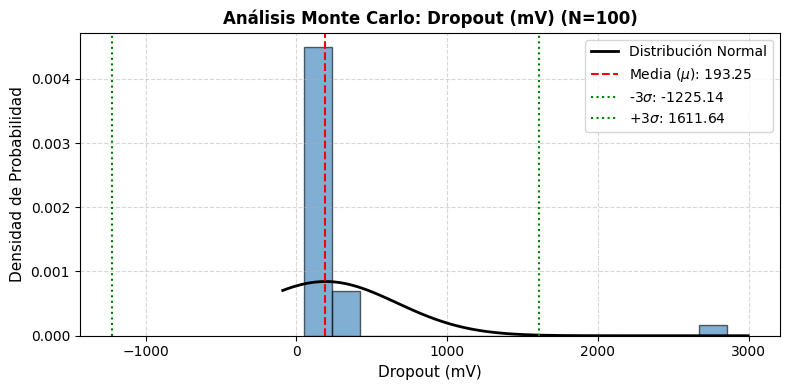

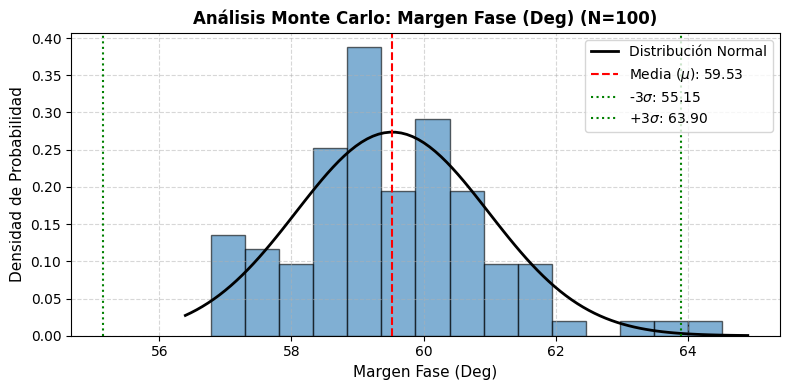

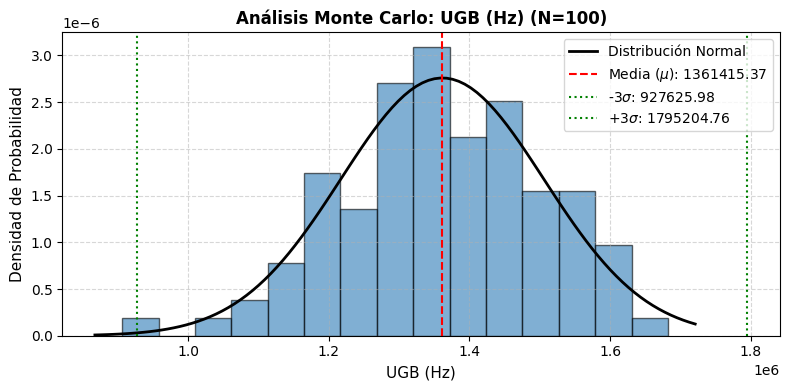

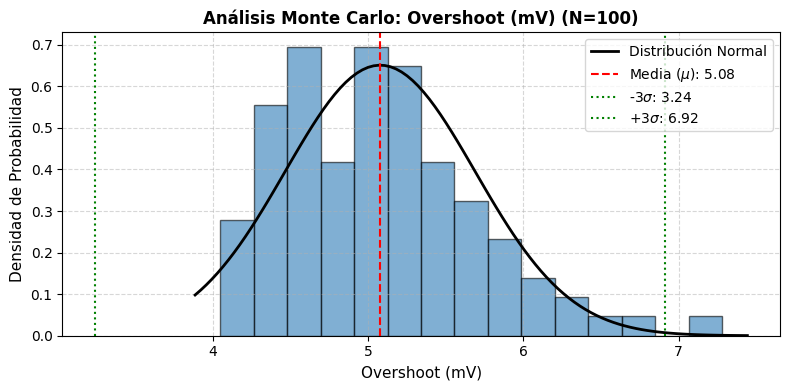

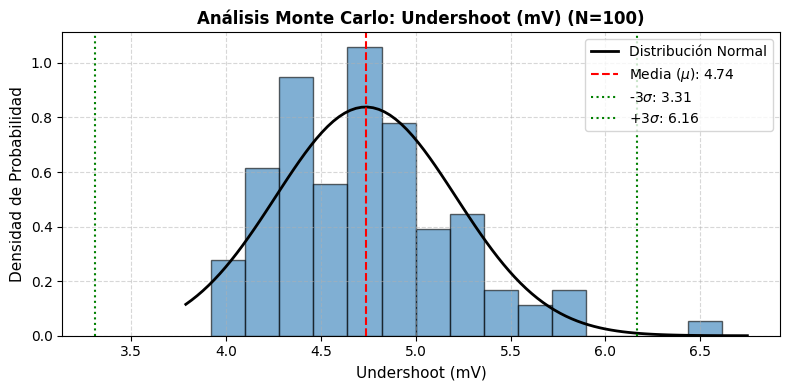

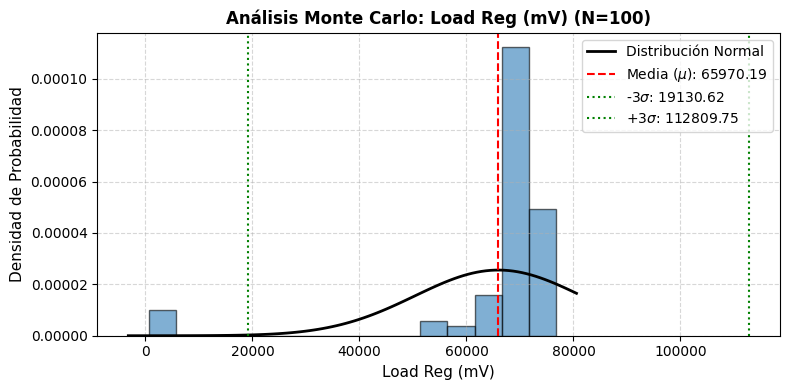

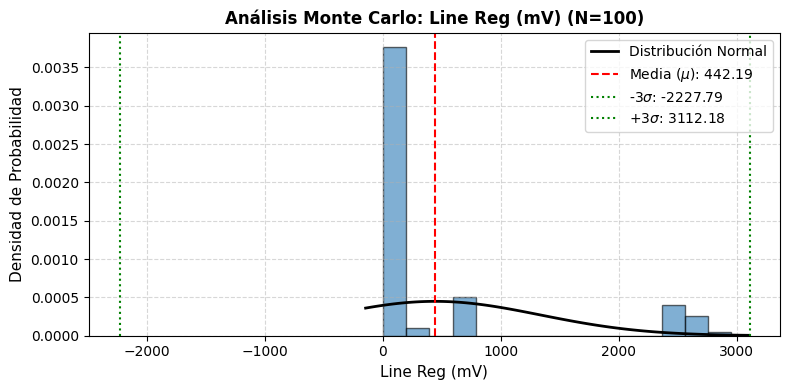

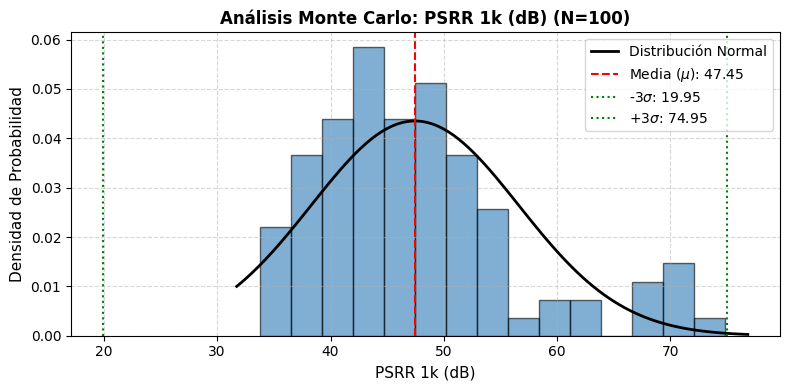

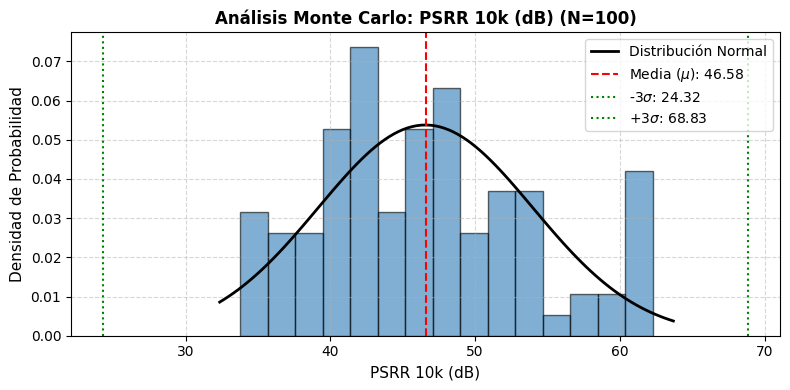

In [3]:

# ==============================================================================
# 2. FUNCIÓN PARA GRAFICAR HISTOGRAMAS Y CAMPANA DE GAUSS
# ==============================================================================
def graficar_gauss(df, columna):
    # Quitamos datos nulos por si alguna simulación falló
    datos = df[columna].dropna() 
    if len(datos) < 2: return
    
    # Cálculos estadísticos
    mu = np.mean(datos)            # Media
    sigma = np.std(datos, ddof=1)  # Desviación estándar
    
    # Configuración del gráfico
    plt.figure(figsize=(8, 4))
    
    # Histograma de los datos reales
    count, bins, ignored = plt.hist(datos, bins=15, density=True, alpha=0.6, color='#2c7bb6', edgecolor='black')
    
    # Curva teórica de Gauss
    xmin, xmax = plt.xlim()
    x = np.linspace(xmin, xmax, 100)
    p = stats.norm.pdf(x, mu, sigma)
    plt.plot(x, p, 'k', linewidth=2, label='Distribución Normal')
    
    # Líneas verticales para Media y Límites de 3 Sigma (99.7% de los chips)
    plt.axvline(mu, color='red', linestyle='dashed', linewidth=1.5, label=f'Media ($\mu$): {mu:.2f}')
    plt.axvline(mu - 3*sigma, color='green', linestyle='dotted', linewidth=1.5, label=f'-3$\sigma$: {mu-3*sigma:.2f}')
    plt.axvline(mu + 3*sigma, color='green', linestyle='dotted', linewidth=1.5, label=f'+3$\sigma$: {mu+3*sigma:.2f}')
    
    # Formato visual
    plt.title(f'Análisis Monte Carlo: {columna} (N={len(datos)})', fontsize=12, fontweight='bold')
    plt.xlabel(columna, fontsize=11)
    plt.ylabel('Densidad de Probabilidad', fontsize=11)
    plt.legend(loc='best')
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

# ==============================================================================
# 3. GENERAR EL REPORTE VISUAL
# ==============================================================================
# Iteramos sobre cada columna para graficarla automáticamente
for columna in df_mc.columns:
    graficar_gauss(df_mc, columna)